In [1]:
import numpy as np
import matplotlib.pyplot as plt
# Set seed for reproducibility
rng = np.random.default_rng(42)
# Generate 10 random points with x and y coordinates
X = rng.uniform(0, 1, size=(10, 2))
print("Generated points:")
print(X)
print("Shape of X:", X.shape)

Generated points:
[[0.77395605 0.43887844]
 [0.85859792 0.69736803]
 [0.09417735 0.97562235]
 [0.7611397  0.78606431]
 [0.12811363 0.45038594]
 [0.37079802 0.92676499]
 [0.64386512 0.82276161]
 [0.4434142  0.22723872]
 [0.55458479 0.06381726]
 [0.82763117 0.6316644 ]]
Shape of X: (10, 2)


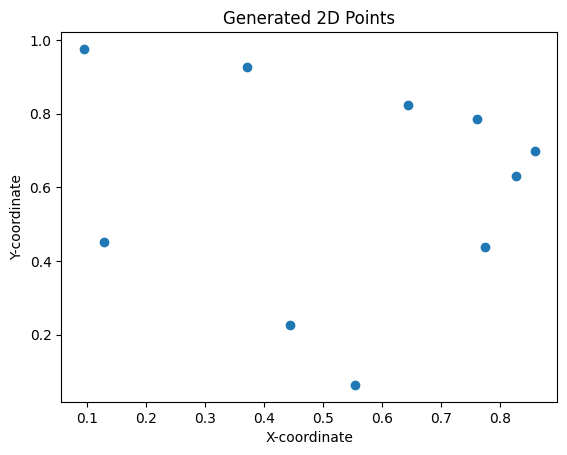

In [2]:
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("X-coordinate")
plt.ylabel("Y-coordinate")
plt.title("Generated 2D Points")
plt.show()

In [6]:
diff = X[:, np.newaxis, :] - X[np.newaxis, :, :]
print("Coordinate differences:", diff.shape)
sq_diff = diff ** 2
print("Squared differences:", sq_diff.shape)
D2_steps = np.sum(sq_diff, axis=2)
print("Summed squared distances:", D2_steps.shape)
print(np.allclose(D2_steps, D2_steps))

Coordinate differences: (10, 10, 2)
Squared differences: (10, 10, 2)
Summed squared distances: (10, 10)
True


In [8]:
diagonal = np.diag(D2_steps)

print("Diagonal:", diagonal)
print("All zeros?", np.allclose(diagonal, 0))

Diagonal: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
All zeros? True


In [10]:
# Create the distance matrix
D2 = np.sum(
    (X[:, np.newaxis, :] - X[np.newaxis, :, :]) ** 2,
    axis=2
)

print("D2 shape:", D2.shape)

D2 shape: (10, 10)


In [11]:
order = np.argsort(D2, axis=1)

print("Sorted indices:")
print(order)

print("First column:", order[:, 0])

Sorted indices:
[[0 9 1 3 7 6 8 5 4 2]
 [1 9 3 6 0 5 7 8 4 2]
 [2 5 4 6 3 9 1 7 0 8]
 [3 6 1 9 0 5 7 2 4 8]
 [4 7 2 5 8 6 0 3 9 1]
 [5 2 6 3 4 1 9 0 7 8]
 [6 3 1 9 5 0 2 7 4 8]
 [7 8 4 0 9 1 6 3 5 2]
 [8 7 0 4 9 1 3 6 5 2]
 [9 1 3 0 6 5 7 8 4 2]]
First column: [0 1 2 3 4 5 6 7 8 9]


In [12]:
K = 2
nearest_argsort = order[:, 1:K + 1]

print("Two nearest neighbours:")
print(nearest_argsort)

Two nearest neighbours:
[[9 1]
 [9 3]
 [5 4]
 [6 1]
 [7 2]
 [2 6]
 [3 1]
 [8 4]
 [7 0]
 [1 3]]


In [13]:
# Select K+1 nearest points, including the point itself
cand = np.argpartition(D2, K, axis=1)[:, :K + 1]

# Get distances of the selected candidates
cand_d = np.take_along_axis(D2, cand, axis=1)

# Sort only these K+1 candidates
local = np.argsort(cand_d, axis=1)
cand_sorted = np.take_along_axis(cand, local, axis=1)

# Remove the point itself
nearest = cand_sorted[:, 1:K + 1]

print("Nearest neighbours:")
print(nearest)

print("Same as argsort result?",
      np.array_equal(nearest, nearest_argsort))

Nearest neighbours:
[[9 1]
 [9 3]
 [5 4]
 [6 1]
 [7 2]
 [2 6]
 [3 1]
 [8 4]
 [7 0]
 [1 3]]
Same as argsort result? True


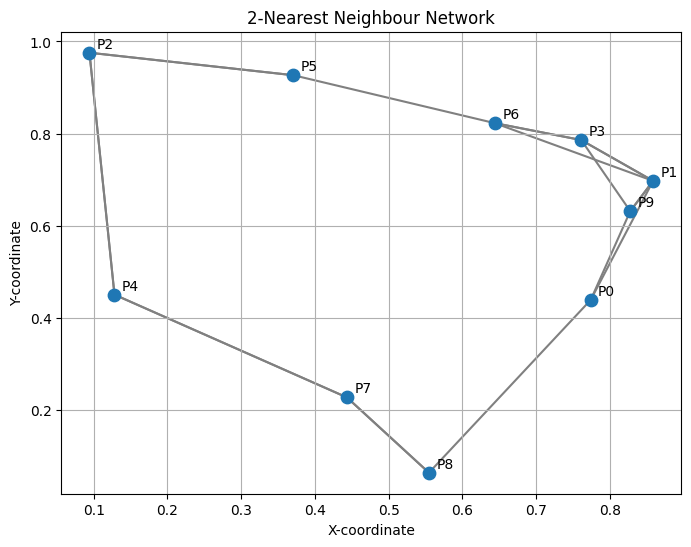

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(X[:, 0], X[:, 1], s=80, zorder=3)

for i in range(len(X)):
    plt.text(X[i, 0] + 0.01, X[i, 1] + 0.01, f"P{i}")

    for j in nearest[i]:
        plt.plot(
            [X[i, 0], X[j, 0]],
            [X[i, 1], X[j, 1]],
            color="gray",
            zorder=1
        )

plt.xlabel("X-coordinate")
plt.ylabel("Y-coordinate")
plt.title("2-Nearest Neighbour Network")
plt.grid(True)
plt.show()


In [20]:
def loop_neighbours(X, K=2):
    N = len(X)
    dist = np.zeros((N, N))

    for i in range(N):
        for j in range(N):
            diff = X[i] - X[j]
            dist[i, j] = np.sum(diff ** 2)

    result = np.zeros((N, K), dtype=int)

    for i in range(N):
        result[i] = np.argsort(dist[i])[1:K + 1]

    return result
def vector_neighbours(X, K=2):
    D2 = np.sum(
        (X[:, np.newaxis, :] - X[np.newaxis, :, :]) ** 2,
        axis=2
    )

    cand = np.argpartition(D2, K, axis=1)[:, :K + 1]
    cand_d = np.take_along_axis(D2, cand, axis=1)

    local = np.argsort(cand_d, axis=1)
    cand_sorted = np.take_along_axis(cand, local, axis=1)

    return cand_sorted[:, 1:K + 1]
# Compare the results of both methods
loop_result = loop_neighbours(X)
vector_result = vector_neighbours(X)

print("Loop-based neighbours:")
print(loop_result)

print("\nVectorised neighbours:")
print(vector_result)

print("\nBoth results are the same:",
      np.array_equal(loop_result, vector_result))
print(np.array_equal(
    loop_neighbours(X),
    vector_neighbours(X)
))


Loop-based neighbours:
[[9 1]
 [9 3]
 [5 4]
 [6 1]
 [7 2]
 [2 6]
 [3 1]
 [8 4]
 [7 0]
 [1 3]]

Vectorised neighbours:
[[9 1]
 [9 3]
 [5 4]
 [6 1]
 [7 2]
 [2 6]
 [3 1]
 [8 4]
 [7 0]
 [1 3]]

Both results are the same: True
True


In [ ]:
for n in [100, 1000, 5000]:

    Xn = np.random.rand(n, 2)

    print(f"\nN = {n}")

    print("Vectorised:")
    %timeit vector_neighbours(Xn)

    print("Loop-based:")
    %timeit loop_neighbours(Xn)



N = 100
Vectorised:
1.49 ms ± 151 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
Loop-based:
195 ms ± 17.5 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)

N = 1000
Vectorised:
140 ms ± 14.1 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
Loop-based:
19.4 s ± 2.1 s per loop (mean ± std. dev. of 7 runs, 1 loop each)

N = 5000
Vectorised:
4.12 s ± 2.09 s per loop (mean ± std. dev. of 7 runs, 1 loop each)
Loop-based:


In [1]:
print("Jupyter is working!")

Jupyter is working!


In [2]:
import numpy as np
from sklearn.neighbors import KDTree

# Generate 1000 points
X1000 = np.random.rand(1000, 2)

K = 2

# Calculate NumPy distance matrix
D2 = np.sum(
    (X1000[:, np.newaxis, :] - X1000[np.newaxis, :, :]) ** 2,
    axis=2
)

# Find 2 nearest neighbours using NumPy
order = np.argsort(D2, axis=1)
numpy_neighbours = order[:, 1:K+1]

# Build KD-Tree
tree = KDTree(X1000, leaf_size=30)

# Find neighbours using KD-Tree
kd_indices = tree.query(
    X1000,
    k=K+1,
    return_distance=False
)

# Remove the point itself
kd_neighbours = kd_indices[:, 1:]

# Display results
print("NumPy neighbours:")
print(numpy_neighbours[:5])

print("\nKD-Tree neighbours:")
print(kd_neighbours[:5])

print("\nResults match:")
print(np.array_equal(numpy_neighbours, kd_neighbours))

NumPy neighbours:
[[808 726]
 [353 285]
 [278  43]
 [407 851]
 [718 780]]

KD-Tree neighbours:
[[808 726]
 [353 285]
 [278  43]
 [407 851]
 [718 780]]

Results match:
True


In [3]:
import time

# NumPy timing
start = time.perf_counter()

D2 = np.sum(
    (X1000[:, np.newaxis, :] - X1000[np.newaxis, :, :]) ** 2,
    axis=2
)

order = np.argsort(D2, axis=1)
numpy_neighbours = order[:, 1:K+1]

numpy_time = time.perf_counter() - start


# KD-Tree timing
start = time.perf_counter()

tree = KDTree(X1000, leaf_size=30)
kd_indices = tree.query(
    X1000,
    k=K+1,
    return_distance=False
)

kd_time = time.perf_counter() - start


print("NumPy time:", numpy_time, "seconds")
print("KD-Tree time:", kd_time, "seconds")

NumPy time: 0.24960869998903945 seconds
KD-Tree time: 0.26415830000769347 seconds
